In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 02 - Italy vs the rest of the EU27: growth, productivity, convergence
Italy in blue, the median of the other 26 members in orange (dashed), all other EU27 countries in gray.

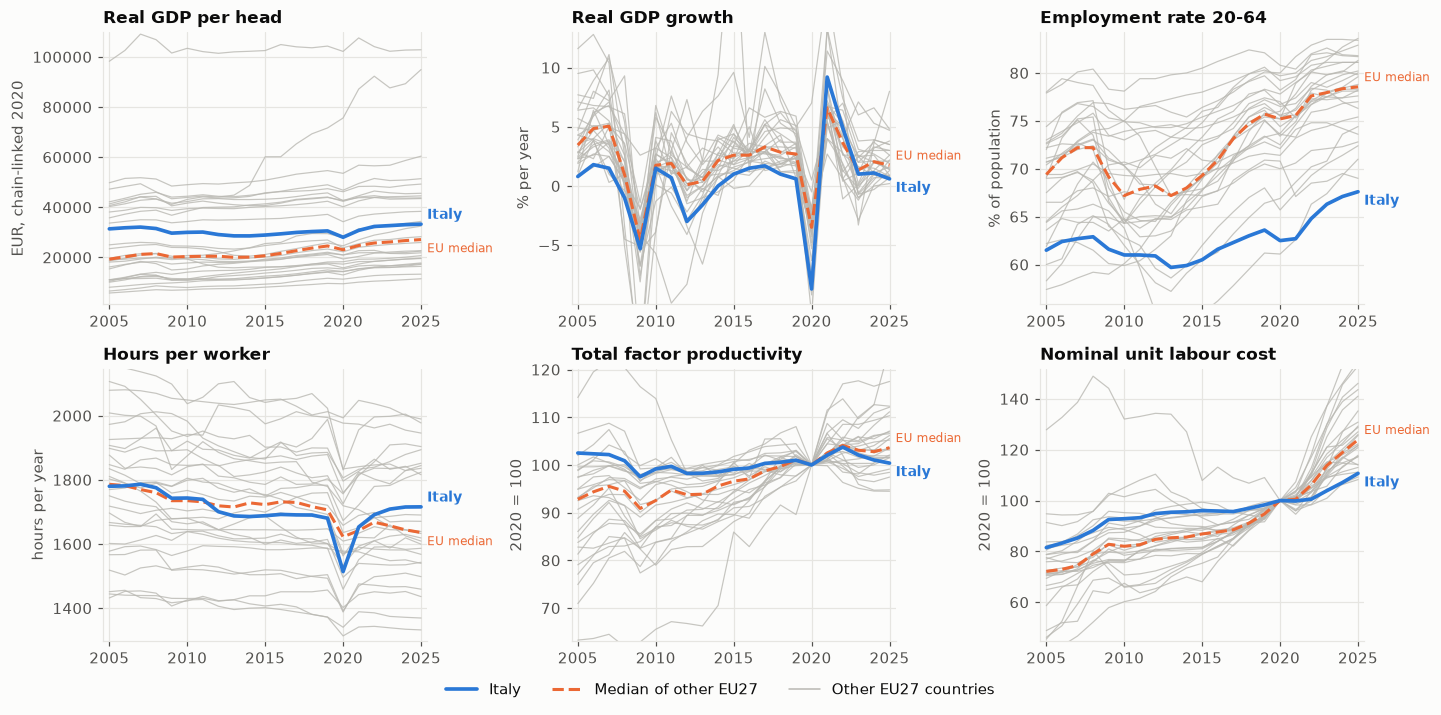

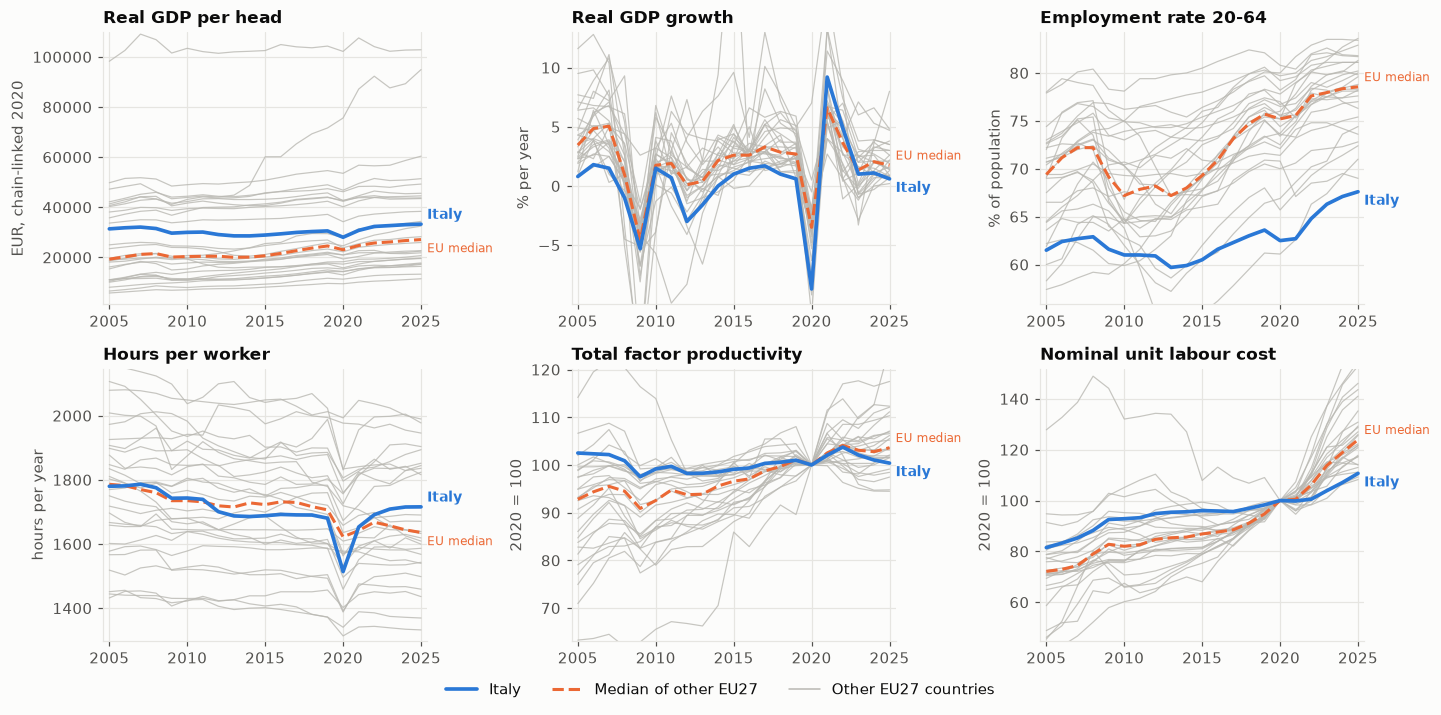

In [2]:
LAST = 2024  # last year with broad coverage (2025 is provisional for many series)
small_multiples(panel, [
    ("gdp_real_pc", "Real GDP per head", "EUR, chain-linked 2020"),
    ("gdp_growth", "Real GDP growth", "% per year"),
    ("employment_rate_20_64", "Employment rate 20-64", "% of population"),
    ("ameco_hours_per_worker", "Hours per worker", "hours per year"),
    ("ameco_tfp_index", "Total factor productivity", "2020 = 100"),
    ("nominal_ulc", "Nominal unit labour cost", "2020 = 100"),
], ncols=3, name="02_growth_overview")

iso3    ITA    DEU    FRA   ESP
year                           
2005  116.6  129.3  126.6  96.2
2010  107.7  129.8  122.9  92.2
2015   99.1  136.8  119.4  84.3
2019   95.0  136.4  113.7  83.9
2024   93.3  130.7  106.2  81.4
2025   92.0  129.8  103.8  82.0


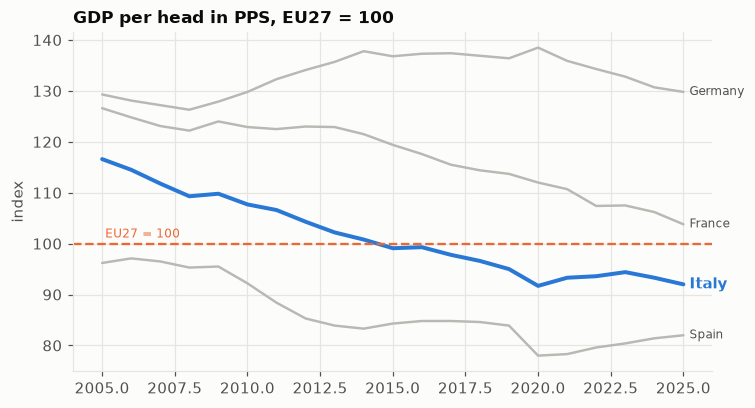

In [3]:
# GDP per head relative to Germany, France, Spain and the EU27 average (EU27 = 100, PPS)
rel = wide(panel, "gdp_pps_pc_eu27")
fig, ax = plt.subplots(figsize=(7.5, 4))
for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain")]:
    ax.plot(rel.index, rel[c], color=PEER_C, lw=1.6); ax.annotate(lab, (rel.index[-1], rel[c].iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
ax.plot(rel.index, rel[ITALY], color=ITALY_C, lw=2.6); ax.annotate("Italy", (rel.index[-1], rel[ITALY].iloc[-1]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
ax.axhline(100, color=EU_C, lw=1.5, ls="--"); ax.annotate("EU27 = 100", (rel.index[0], 100), xytext=(2, 4), textcoords="offset points", color=EU_C, fontsize=8)
ax.set_title("GDP per head in PPS, EU27 = 100"); ax.set_ylabel("index"); save(fig, "02_convergence")
print(rel.loc[[2005, 2010, 2015, 2019, 2024, 2025], [ITALY, "DEU", "FRA", "ESP"]].round(1))

*Caveat:* the EU27 average itself rises as central/eastern members catch up, so part of Italy's fall in this index is their gain, not Italy's loss. Compare with Germany/France/Spain, which are the more telling references.

,employment rate,hours per worker,productivity & demography (residual),real GDP per head
iso3,,,,
ITA,9.5,-3.7,0.0,5.8
DEU,15.6,-7.2,11.8,20.1
FRA,8.3,-1.3,6.1,13.0
ESP,7.0,-5.1,10.3,12.3
PRT,9.8,0.3,7.6,17.7
GRC,9.8,-9.1,-0.1,0.6
EU median (excl. IT),9.9,-5.5,22.7,32.7


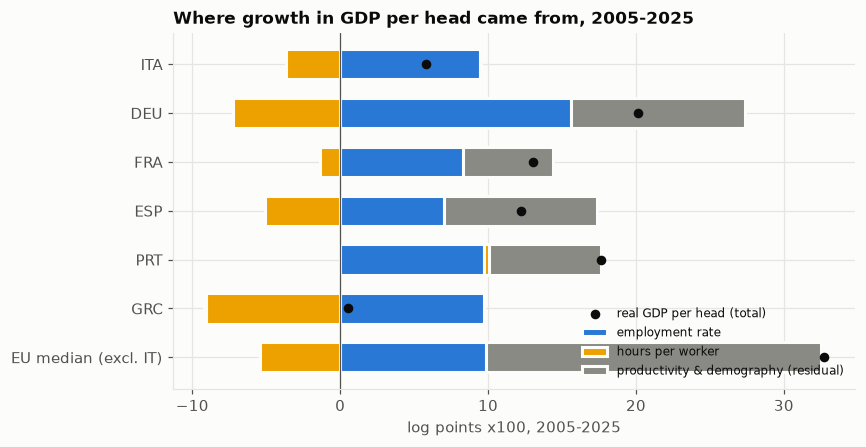

In [4]:
# Where does the GDP-per-head gap come from? Log change 2005-2025 (2025 a first estimate) split into employment rate, hours, and a productivity residual
dec = gdp_pc_growth_decomposition(panel, 2005, 2025)
parts = ["employment rate", "hours per worker", "productivity & demography (residual)"]
show = dec.loc[["ITA", "DEU", "FRA", "ESP", "PRT", "GRC"]].copy()
show.loc["EU median (excl. IT)"] = dec.drop("ITA").median()
fig, ax = plt.subplots(figsize=(8, 4.2))
cols = ["#2a78d6", "#eda100", "#8a8a85"]
left_pos = np.zeros(len(show)); left_neg = np.zeros(len(show))
for part, col in zip(parts, cols):
    v = show[part].values; base = np.where(v >= 0, left_pos, left_neg)
    ax.barh(range(len(show)), v, left=base, color=col, height=0.62, label=part, edgecolor=SURFACE, linewidth=2)
    left_pos += np.where(v >= 0, v, 0); left_neg += np.where(v < 0, v, 0)
ax.scatter(show["real GDP per head"], range(len(show)), color=INK, zorder=5, s=28, label="real GDP per head (total)")
ax.set_yticks(range(len(show)), show.index); ax.invert_yaxis(); ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("log points x100, 2005-2025"); ax.set_title("Where growth in GDP per head came from, 2005-2025")
ax.legend(loc="lower right", fontsize=8); save(fig, "02_growth_decomposition")
display(show.round(1))

In [5]:
# Italy's rank among EU27 members, selected years (1 = highest; index series such as TFP and ULC are 2020=100, so ranks are not meaningful)
rows = {}
for ind in ["gdp_real_pc", "gdp_growth", "employment_rate_20_64", "employment_rate_20_64_female", "ameco_hours_per_worker", "hicp_inflation"]:
    w = wide(panel, ind)
    rows[ind] = {y: "%d/%d" % italy_rank(w, y) for y in (2005, 2010, 2015, 2019, 2024, 2025) if not np.isnan(w.loc[y, ITALY])}
display(pd.DataFrame(rows).T)

,2005,2010,2015,2019,2024,2025
gdp_real_pc,11/27,11/27,11/27,11/27,12/27,12/27
gdp_growth,26/27,18/27,25/27,27/27,19/27,26/27
employment_rate_20_64,24/27,25/27,25/27,26/27,27/27,27/27
employment_rate_20_64_female,26/27,26/27,26/27,26/27,27/27,27/27
ameco_hours_per_worker,14/27,14/27,16/27,15/27,11/27,11/27
hicp_inflation,16/27,18/27,13/27,24/27,25/27,25/27


In [6]:
# Figures quoted in the takeaways: Italy, median of the other members, rank (1 = highest) among the members with a value
def quoted(ind, years, countries=()):
    w = wide(panel, ind, EU27_ISO3)
    for y in years:
        r = w.loc[y].dropna()
        print(f"{ind} {y}: Italy {r[ITALY]:.2f} | median of the others {r.drop(ITALY).median():.2f} | rank {int(r.rank(ascending=False)[ITALY])}/{len(r)}" + "".join(f" | {c} {r[c]:.2f}" for c in countries))  # two decimals: a takeaway rounded to one is then checked without ties
quoted("employment_rate_20_64", [2025]); quoted("employment_rate_20_64_female", [2025])
for end in (2024, 2025):
    d = gdp_pc_growth_decomposition(panel, 2005, end); t = d["real GDP per head"]
    print(f"real GDP per head 2005-{end}, log points x100: Italy {t[ITALY]:+.1f} | median of the others {t.drop(ITALY).median():+.1f} (true change {(np.exp(t.drop(ITALY).median() / 100) - 1) * 100:+.1f}%) | " + ", ".join(f"{c} {t[c]:+.1f}" for c in ("GRC", "LUX", "DEU", "CYP", "CZE", "PRT", "FRA", "ESP")))

employment_rate_20_64 2025: Italy 67.60 | median of the others 78.55 | rank 27/27
employment_rate_20_64_female 2025: Italy 58.00 | median of the others 75.70 | rank 27/27
real GDP per head 2005-2024, log points x100: Italy +5.2 | median of the others +29.9 (true change +34.9%) | GRC -1.4, LUX +4.4, DEU +19.9, CYP +29.3, CZE +30.5, PRT +16.8, FRA +12.5, ESP +10.7
real GDP per head 2005-2025, log points x100: Italy +5.8 | median of the others +32.7 (true change +38.7%) | GRC +0.6, LUX +4.6, DEU +20.1, CYP +32.4, CZE +33.0, PRT +17.7, FRA +13.0, ESP +12.3


## Takeaways (numbers from the cells above; Eurostat/AMECO, 2005-2025, 2025 a first estimate)
- **Italy is not poor, it is stagnant.** Real GDP per head is mid-table (11th-12th of 27 throughout, 12th in 2025) but grew only +5.8 log points over 2005-2025 (+6.0%), against +32.7 (+38.7%) for the median of the other members, +20.1 Germany, +17.7 Portugal, +13.0 France, +12.3 Spain. Of the 27 members only Greece (+0.6) and Luxembourg (+4.6, from a very high base) were lower. (In log points x100 throughout; to 2024 the figures were +5.2 against +29.9. The median of the others rose by about 3 points with Eurostat's release of 5 November 2026, which revised Cyprus from +26.5 to +32.4: the median is the midpoint of Cyprus and Czechia, +33.0, with Germany, +20.1, the next below.)
- **The shortfall is in the productivity/demography residual**, not hours or employment: +0.0 for Italy vs +22.7 for the median. Employment added +9.5 (median +9.9) and hours -3.7 (median -5.5). The residual mixes output per hour with age-structure effects, so it cannot say how much is each.
- **Employment is the structural gap in levels:** 20-64 employment was 67.6% in 2025 against a 78.6% median (27th of 27); female employment 58.0% vs 75.7% (also last).
- **Convergence went backwards:** GDP per head in PPS (EU27 = 100) fell from 116.6 in 2005 to 92.2 in 2025, while Germany stayed near 130. Part of this is eastern members catching up, but Spain and France show smaller falls than Italy relative to Germany.